In [154]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

In [155]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


from sklearn.model_selection import GridSearchCV, StratifiedKFold, RandomizedSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb

In [156]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
) # Validation

In [157]:
url = "/content/fetal_health.csv"
df = pd.read_csv(url)

df.columns = df.columns.str.lower().str.replace(" ", "_")

In [158]:
df.columns

Index(['baseline_value', 'accelerations', 'fetal_movement',
       'uterine_contractions', 'light_decelerations', 'severe_decelerations',
       'prolongued_decelerations', 'abnormal_short_term_variability',
       'mean_value_of_short_term_variability',
       'percentage_of_time_with_abnormal_long_term_variability',
       'mean_value_of_long_term_variability', 'histogram_width',
       'histogram_min', 'histogram_max', 'histogram_number_of_peaks',
       'histogram_number_of_zeroes', 'histogram_mode', 'histogram_mean',
       'histogram_median', 'histogram_variance', 'histogram_tendency',
       'fetal_health'],
      dtype='object')

In [159]:
# quick dataframe statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
baseline_value,2126.0,133.303857,9.840844,106.0,126.000,133.000,140.000,160.000
accelerations,2126.0,0.003178,0.003866,0.0,0.000,0.002,0.006,0.019
fetal_movement,2126.0,0.009481,0.046666,0.0,0.000,0.000,0.003,0.481
uterine_contractions,2126.0,0.004366,0.002946,0.0,0.002,0.004,0.007,0.015
light_decelerations,2126.0,0.001889,0.002960,0.0,0.000,0.000,0.003,0.015
severe_decelerations,2126.0,0.000003,0.000057,0.0,0.000,0.000,0.000,0.001
prolongued_decelerations,2126.0,0.000159,0.000590,0.0,0.000,0.000,0.000,0.005
abnormal_short_term_variability,2126.0,46.990122,17.192814,12.0,32.000,49.000,61.000,87.000
mean_value_of_short_term_variability,2126.0,1.332785,0.883241,0.2,0.700,1.200,1.700,7.000
percentage_of_time_with_abnormal_long_term_variability,2126.0,9.846660,18.396880,0.0,0.000,0.000,11.000,91.000


In [160]:
# Null check
df.isnull().sum()

,0
baseline_value,0
accelerations,0
fetal_movement,0
uterine_contractions,0
light_decelerations,0
severe_decelerations,0
prolongued_decelerations,0
abnormal_short_term_variability,0
mean_value_of_short_term_variability,0
percentage_of_time_with_abnormal_long_term_variability,0


In [161]:
# correlation to target
features_list = ['prolongued_decelerations', 'accelerations', 'uterine_contractions', 'light_decelerations', 'fetal_movement', 'severe_decelerations', 'baseline_value']
df[features_list].corrwith(df['fetal_health']).sort_values(ascending=False)

,0
prolongued_decelerations,0.484859
baseline_value,0.148151
severe_decelerations,0.131934
fetal_movement,0.088010
light_decelerations,0.058870
uterine_contractions,-0.204894
accelerations,-0.364066


In [162]:
# Class Imbalance Sanity Check
df['fetal_health'].value_counts(normalize=True)

,proportion
fetal_health,
1.0,0.778457
2.0,0.138758
3.0,0.082785


In [163]:
# TRAINING PHASE

In [164]:
# Split features and labels directly from the cleaned raw train dataset

# X_raw = df.drop(columns=['fetal_health'])
X_raw = df[features_list]

y_raw = df['fetal_health'].values

# Holdout test set creation (20% of dataset)
X_raw_full_train, X_raw_test, y_full_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=1, stratify=y_raw
)

# Split remaining 80% to 60% Train, 20% Validation
X_raw_train, X_raw_val, y_train, y_val = train_test_split(
    X_raw_full_train, y_full_train, test_size=0.25, random_state=1, stratify=y_full_train
)

In [165]:
# len(X_raw_train), len(X_raw_val), len(X_raw_test)

In [166]:
preprocessing_pipeline = Pipeline([
    ('vectorizer', DictVectorizer(sparse=False)),
    ('scaler', StandardScaler())
])

In [167]:
# LOGISTIC REGRESSION

In [168]:
# Assemble clean Pipeline leveraging our preprocessing_pipeline
logistic_reg_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42))
])

# Convert DataFrame to list of dictionaries and train our initial model
X_dict_train = X_raw_train.to_dict(orient='records')
logistic_reg_pipeline.fit(X_dict_train, y_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('vectorizer', DictVectorizer(sparse=False)),
                                 ('scaler', StandardScaler())])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

In [169]:
X_dict_train = X_raw_train.to_dict(orient='records')
y_train_proba = logistic_reg_pipeline.predict_proba(X_dict_train)

X_dict_val = X_raw_val.to_dict(orient='records')
y_val_proba = logistic_reg_pipeline.predict_proba(X_dict_val)

X_dict_test = X_raw_test.to_dict(orient='records')
y_test_proba = logistic_reg_pipeline.predict_proba(X_dict_test)

print("Training ROC-AUC:", roc_auc_score(y_train, y_train_proba, multi_class='ovr'))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba, multi_class='ovr'))
print("Test ROC-AUC:", roc_auc_score(y_test, y_test_proba, multi_class='ovr'))

Training ROC-AUC: 0.9237200010500137
Validation ROC-AUC: 0.9170730436376049
Test ROC-AUC: 0.9380980375580387


In [170]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__class_weight': [None, 'balanced']
}

grid_search_lr = GridSearchCV(
    estimator=logistic_reg_pipeline,
    param_grid=param_grid,
    scoring='roc_auc_ovr',
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search_lr.fit(X_dict_train, y_train)
print("Best parameters:", grid_search_lr.best_params_)

# Train final Logistic Regression on Full Train Data
final_lr = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', LogisticRegression(max_iter=2000, C=0.01, class_weight=None, random_state=42))
])

X_dict_full_train = X_raw_full_train.to_dict(orient='records')
X_dict_test = X_raw_test.to_dict(orient='records')

final_lr.fit(X_dict_full_train, y_full_train)

Best parameters: {'classifier__C': 1, 'classifier__class_weight': None}


Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('vectorizer', DictVectorizer(sparse=False)),
                                 ('scaler', StandardScaler())])),
                ('classifier',
                 LogisticRegression(C=0.01, max_iter=2000, random_state=42))])

In [171]:
# Compute metric comparison on test set
y_full_pred = final_lr.predict_proba(X_dict_test)
y_pred = logistic_reg_pipeline.predict_proba(X_dict_test)

print(f"AUC before tuning: {roc_auc_score(y_test, y_pred, multi_class="ovr"):.4f}")
print(f"AUC after tuning: {roc_auc_score(y_test, y_full_pred, multi_class="ovr"):.4f}")

AUC before tuning: 0.9382
AUC after tuning: 0.9354


In [172]:
# DECISION TREE

In [173]:
decision_tree_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', DecisionTreeClassifier(random_state=42))
])
decision_tree_pipeline.fit(X_dict_train, y_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('vectorizer', DictVectorizer(sparse=False)),
                                 ('scaler', StandardScaler())])),
                ('classifier', DecisionTreeClassifier(random_state=42))])

In [174]:
y_train_proba = decision_tree_pipeline.predict_proba(X_dict_train)
y_val_proba = decision_tree_pipeline.predict_proba(X_dict_val)

print("Training ROC-AUC:", roc_auc_score(y_train, y_train_proba, multi_class='ovr'))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba, multi_class='ovr'))

# There is a huge gap between them, hence a sign of overfitting

Training ROC-AUC: 0.9984307703051808
Validation ROC-AUC: 0.80691641156772


In [175]:
# Optimization for Decision Tree Hyperparameters
param_grid_dt = {
    'classifier__max_depth': [5, 10, 15],
    'classifier__min_samples_leaf': [5, 10, 20],
    'classifier__criterion': ['gini', 'entropy']
}

grid_search_dt = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=param_grid_dt,
    scoring='roc_auc_ovr',
    cv=cv,
    n_jobs=-1
)
grid_search_dt.fit(X_dict_train, y_train)
print("Best parameters:", grid_search_dt.best_params_)

# Train final Decision Tree using the parameters chosen dynamically by GridSearchCV
final_dt = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        max_depth=grid_search_dt.best_params_['classifier__max_depth'],
        min_samples_leaf=grid_search_dt.best_params_['classifier__min_samples_leaf'],
        criterion=grid_search_dt.best_params_['classifier__criterion']
    ))
])
final_dt.fit(X_dict_full_train, y_full_train)


Best parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 20}


Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('vectorizer', DictVectorizer(sparse=False)),
                                 ('scaler', StandardScaler())])),
                ('classifier',
                 DecisionTreeClassifier(criterion='entropy', max_depth=10,
                                        min_samples_leaf=20,
                                        random_state=42))])

In [176]:
# Compute metric comparison on test set
y_full_pred = final_dt.predict_proba(X_dict_test)
y_pred = decision_tree_pipeline.predict_proba(X_dict_test)

print(f"AUC before tuning: {roc_auc_score(y_test, y_pred, multi_class="ovr"):.4f}")
print(f"AUC after tuning: {roc_auc_score(y_test, y_full_pred, multi_class="ovr"):.4f}")

AUC before tuning: 0.8539
AUC after tuning: 0.9301


In [177]:
# RANDOM FOREST

In [178]:
random_forest_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])
random_forest_pipeline.fit(X_dict_train, y_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('vectorizer', DictVectorizer(sparse=False)),
                                 ('scaler', StandardScaler())])),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])

In [179]:
y_train_proba = random_forest_pipeline.predict_proba(X_dict_train)
y_val_proba = random_forest_pipeline.predict_proba(X_dict_val)

print("Training ROC-AUC:", roc_auc_score(y_train, y_train_proba, multi_class='ovr'))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba, multi_class='ovr'))


Training ROC-AUC: 0.9979390780786578
Validation ROC-AUC: 0.9260656721268127


In [180]:
# Swapped GridSearch for RandomizedSearchCV to avoid long 30+ minute delays
param_grid_rf = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_leaf': [1, 5],
    'classifier__class_weight': [None, 'balanced']
}

random_search_rf = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=param_grid_rf,
    n_iter=8,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    random_state=42
)
random_search_rf.fit(X_dict_train, y_train)
print("Best RF parameters:", random_search_rf.best_params_)


# Train final RF on full training dataset programmatically extracting parameters
final_rf = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_estimators=random_search_rf.best_params_['classifier__n_estimators'],
        max_depth=random_search_rf.best_params_['classifier__max_depth'],
        min_samples_leaf=random_search_rf.best_params_['classifier__min_samples_leaf'],
        class_weight=random_search_rf.best_params_['classifier__class_weight'],
        n_jobs=-1
    ))
])
final_rf.fit(X_dict_full_train, y_full_train)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan]
  warnings.warn(


Best RF parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': None, 'classifier__class_weight': None}


Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('vectorizer', DictVectorizer(sparse=False)),
                                 ('scaler', StandardScaler())])),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])

In [181]:
# Compute metric comparison on test set
y_full_pred = final_rf.predict_proba(X_dict_test)
y_pred = random_forest_pipeline.predict_proba(X_dict_test)

print(f"AUC before tuning: {roc_auc_score(y_test, y_pred, multi_class="ovr"):.4f}")
print(f"AUC after tuning: {roc_auc_score(y_test, y_full_pred, multi_class="ovr"):.4f}")

AUC before tuning: 0.9446
AUC after tuning: 0.9516


In [182]:
# XGBOOST

In [183]:
# XGBoost expects 0-indexed targets (e.g., [0, 1, 2]), but y is [1.0, 2.0, 3.0].
# We will shift the labels by subtracting 1 for XGBoost.
y_train_xgb = (y_train - 1).astype(int)
y_val_xgb = (y_val - 1).astype(int)
y_full_train_xgb = (y_full_train - 1).astype(int)
y_test_xgb = (y_test - 1).astype(int)

xgboost_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss'))
])
xgboost_pipeline.fit(X_dict_train, y_train_xgb)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('vectorizer', DictVectorizer(sparse=False)),
                                 ('scaler', StandardScaler())])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               fe...None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [184]:
y_train_proba = xgboost_pipeline.predict_proba(X_dict_train)
y_val_proba = xgboost_pipeline.predict_proba(X_dict_val)

print("Training ROC-AUC:", roc_auc_score(y_train, y_train_proba, multi_class='ovr'))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba, multi_class='ovr'))


Training ROC-AUC: 0.9973593844708205
Validation ROC-AUC: 0.9420277826013578


In [185]:
# Optimize XGBoost parameters dynamically
param_grid_xgb = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 6],
    'classifier__learning_rate': [0.05, 0.1]
}

grid_search_xgb = GridSearchCV(
    estimator=xgboost_pipeline,
    param_grid=param_grid_xgb,
    scoring='roc_auc_ovr',
    cv=cv,
    n_jobs=-1
)
grid_search_xgb.fit(X_dict_train, y_train_xgb)
print("Best XGB parameters:", grid_search_xgb.best_params_)


# Train final XGB model natively utilizing best grid params
final_xgb = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('classifier', xgb.XGBClassifier(
        random_state=42,
        n_estimators=grid_search_xgb.best_params_['classifier__n_estimators'],
        max_depth=grid_search_xgb.best_params_['classifier__max_depth'],
        learning_rate=grid_search_xgb.best_params_['classifier__learning_rate'],
        eval_metric='logloss',
        n_jobs=-1
    ))
])
final_xgb.fit(X_dict_full_train, y_full_train_xgb)

Best XGB parameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 6, 'classifier__n_estimators': 100}


Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('vectorizer', DictVectorizer(sparse=False)),
                                 ('scaler', StandardScaler())])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               fe...hts=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [186]:
# Compute metric comparison on test set
y_full_pred = final_xgb.predict_proba(X_dict_test)
y_pred = xgboost_pipeline.predict_proba(X_dict_test)

print(f"AUC before tuning: {roc_auc_score(y_test, y_pred, multi_class="ovr"):.4f}")
print(f"AUC after tuning: {roc_auc_score(y_test, y_full_pred, multi_class="ovr"):.4f}")

AUC before tuning: 0.9608
AUC after tuning: 0.9660


In [187]:
# Map our comparison models using updated pipelines
models = {
    "Logistic Regression": final_lr,
    "Decision Tree": final_dt,
    "Random Forest": final_rf,
    "XGBoost": final_xgb
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_dict_test)
    y_prob = model.predict_proba(X_dict_test)

    # Convert XGBoost predictions back to 1-indexed format to match y_test
    if name == "XGBoost":
        y_pred = y_pred + 1

    predictions[name] = {
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='macro', zero_division=0),
        "Recall": recall_score(y_test, y_pred, average='macro', zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average='macro', zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob, multi_class='ovr')
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4).sort_values(by="F1-Score", ascending=False))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,0.9038,0.8433,0.8125,0.8251,0.9516
XGBoost,0.9061,0.8189,0.8181,0.8180,0.9660
Decision Tree,0.8638,0.7654,0.7180,0.7335,0.9301
Logistic Regression,0.8592,0.8148,0.6060,0.6690,0.9354


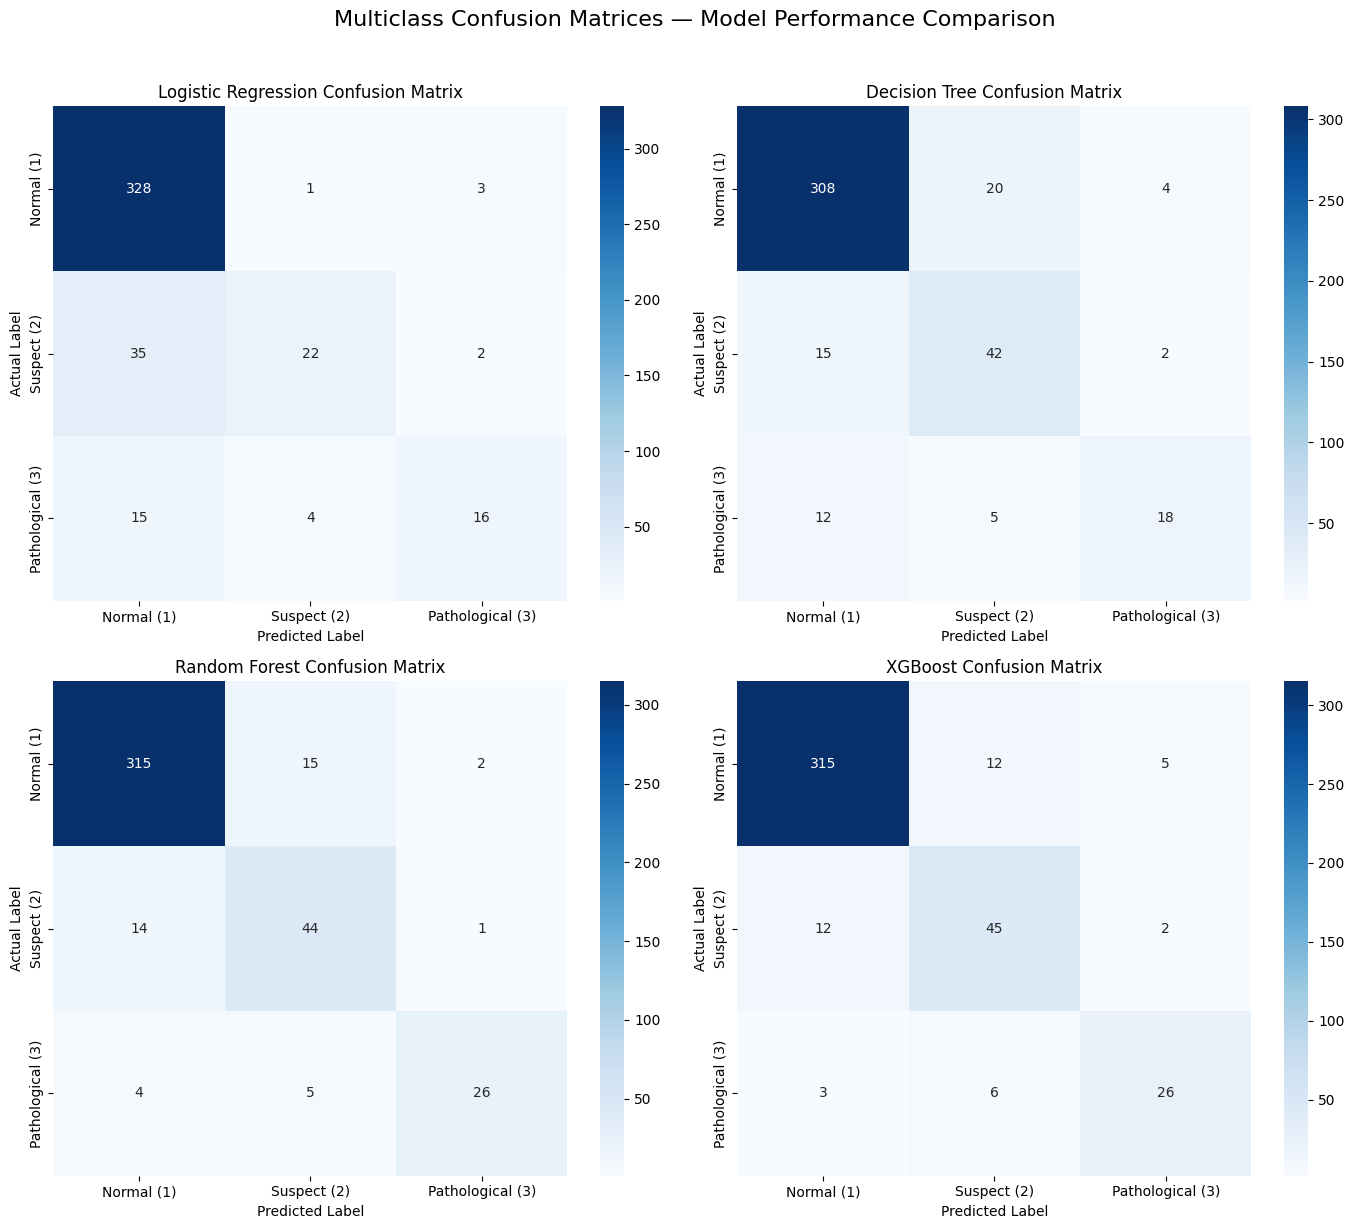

In [188]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

class_names = ["Normal (1)", "Suspect (2)", "Pathological (3)"]

for ax, (name, model) in zip(axes, models.items()):
    y_pred = predictions[name]["y_pred"]
    # Calculate multiclass confusion matrix using the actual classes [1, 2, 3]
    cm = confusion_matrix(y_test, y_pred, labels=[1.0, 2.0, 3.0])

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )
    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Multiclass Confusion Matrices — Model Performance Comparison", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [189]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

for name, model in models.items():
    y_pred = predictions[name]["y_pred"]
    y_prob = predictions[name]["y_prob"]

    # Generate 3x3 confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[1.0, 2.0, 3.0])

    # Clinical Definitions from confusion matrix:
    # Row 0: True Normal (1.0), Row 1: True Suspect (2.0), Row 2: True Pathological (3.0)
    # Col 0: Pred Normal (1.0), Col 1: Pred Suspect (2.0), Col 2: Pred Pathological (3.0)

    # False Reassurance (Clinical Risk): True is Suspect or Pathological, but predicted as Normal
    # This corresponds to cm[1, 0] (True Suspect pred Normal) + cm[2, 0] (True Pathological pred Normal)
    false_reassurances = int(cm[1, 0] + cm[2, 0])

    # False Alarm (Over-diagnosing): True is Normal, but predicted as Suspect or Pathological
    # This corresponds to cm[0, 1] (True Normal pred Suspect) + cm[0, 2] (True Normal pred Pathological)
    false_alarms = int(cm[0, 1] + cm[0, 2])

    print(f"=== {name} Detailed Clinical Metrics ===")
    print(f"False Reassurances (True Suspect/Pathological predicted Normal): {false_reassurances}")
    print(f"False Alarms (True Normal predicted Suspect/Pathological): {false_alarms}")

    # Class-wise metrics
    report = classification_report(y_test, y_pred, labels=[1.0, 2.0, 3.0], output_dict=True, zero_division=0)
    for c in ['1.0', '2.0', '3.0']:
        label = "Normal (1.0)" if c == '1.0' else "Suspect (2.0)" if c == '2.0' else "Pathological (3.0)"
        print(f"  Class {label}: Precision = {report[c]['precision']:.4f}, Recall = {report[c]['recall']:.4f}")

    # Overall macro averages
    print(f"  Overall Accuracy: {report['accuracy']:.4f}")
    print(f"  Macro Precision: {report['macro avg']['precision']:.4f}")
    print(f"  Macro Recall (Sensitivity): {report['macro avg']['recall']:.4f}")
    print("-" * 50)

=== Logistic Regression Detailed Clinical Metrics ===
False Reassurances (True Suspect/Pathological predicted Normal): 50
False Alarms (True Normal predicted Suspect/Pathological): 4
  Class Normal (1.0): Precision = 0.8677, Recall = 0.9880
  Class Suspect (2.0): Precision = 0.8148, Recall = 0.3729
  Class Pathological (3.0): Precision = 0.7619, Recall = 0.4571
  Overall Accuracy: 0.8592
  Macro Precision: 0.8148
  Macro Recall (Sensitivity): 0.6060
--------------------------------------------------
=== Decision Tree Detailed Clinical Metrics ===
False Reassurances (True Suspect/Pathological predicted Normal): 27
False Alarms (True Normal predicted Suspect/Pathological): 24
  Class Normal (1.0): Precision = 0.9194, Recall = 0.9277
  Class Suspect (2.0): Precision = 0.6269, Recall = 0.7119
  Class Pathological (3.0): Precision = 0.7500, Recall = 0.5143
  Overall Accuracy: 0.8638
  Macro Precision: 0.7654
  Macro Recall (Sensitivity): 0.7180
----------------------------------------------

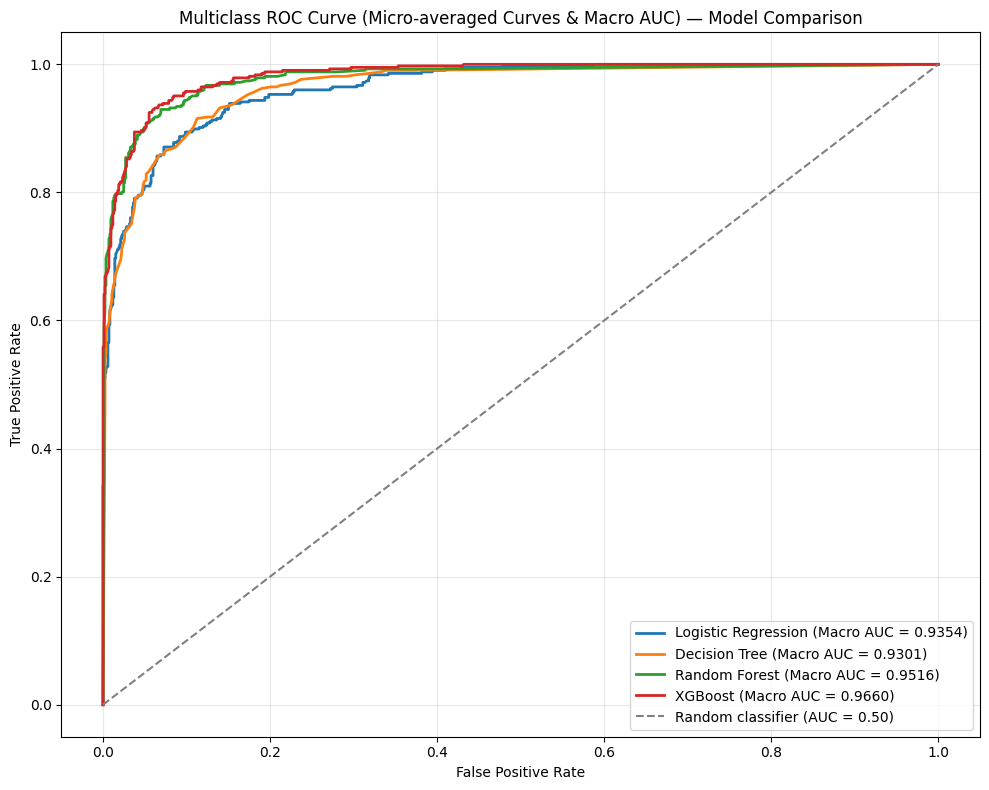

In [190]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize

# Binarize the output for multiclass ROC curves
classes = [1.0, 2.0, 3.0]
y_test_binarized = label_binarize(y_test, classes=classes)
n_classes = y_test_binarized.shape[1]

plt.figure(figsize=(10, 8))

colors = ['blue', 'green', 'orange', 'red']
model_names = list(models.keys())

for model_idx, name in enumerate(model_names):
    y_prob = predictions[name]["y_prob"]

    # Calculate micro-average ROC curve
    fpr, tpr, _ = roc_curve(y_test_binarized.ravel(), y_prob.ravel())
    auc_score = roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro')

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (Macro AUC = {auc_score:.4f})"
    )

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random classifier (AUC = 0.50)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve (Micro-averaged Curves & Macro AUC) — Model Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [191]:
# Serialization of the final pipeline containing all Feature Extraction steps inside
import joblib
import os

# Create the models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the integrated pipeline
joblib.dump(
    {
        "model": final_xgb,

    },
    "../models/xgboost_pipeline.joblib"
)
print("Successfully saved integrated pipeline to xgboost_pipeline.joblib")

Successfully saved integrated pipeline to xgboost_pipeline.joblib
